In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import missingno as msno
from pathlib import Path

In [2]:
try:
    df = pd.read_excel('../data/processed/5_year_mine_data_cleaned.xlsx')
    print("Data Frame Head : ")
    print(df.head())
    print("Data Frame Tail : ")
    print(df.tail())
    print("Data Frames Samples : ")
    print(df.sample())
    print("Data Frame Information : ")
    print(df.info())
    print("Data Frame Description : ")
    print(df.describe())

except FileNotFoundError:
    print("Error: The CSV file not found.")
except pd.errors.EmptyDataError:
    print("Error: The CSV file is empty.")
except pd.errors.ParserError:
    print("Error: The CSV file is malformed.")
except Exception as e:
    print(f"Unexpected error occurred: {e}")

Data Frame Head : 
     YEAR  SEASON     MONTH   LOCATION  WEEK  Temperature  Relative_humidity  \
0     NaN     NaN       NaN        NaN   NaN          NaN                NaN   
1  2023.0  WINTER  DECEMBER  HAUL ROAD   1.0         30.1               64.5   
2  2023.0  WINTER  DECEMBER  HAUL ROAD   1.0         29.2               70.3   
3  2023.0  WINTER  DECEMBER  HAUL ROAD   2.0         27.6               68.0   
4  2023.0  WINTER  DECEMBER  HAUL ROAD   2.0         24.5               85.3   

   RF-CUMULATIVE  Wind_speed  Road_width  Distance  Production  \
0            NaN         NaN         NaN       NaN         NaN   
1            1.0        2.55        12.5      25.0    157650.0   
2            1.0        2.55        12.5      25.0    157650.0   
3            0.0        2.55        12.5      25.0    157650.0   
4            0.0        2.55        12.5      25.0    157650.0   

   Vehicle Capacity  PM10  PM2.5  
0                 1   NaN    NaN  
1             25000  56.8   42.6 

In [3]:
print("="*80)
print("DATASET SHAPE")
print(df.shape)
print("="*80)


print("="*80)
print("FIRST FIVE ROWS")
print(df.head())
print("="*80)

print("="*80)
print("LAST FIVE ROWS")
print(df.tail())
print("="*80)


print("="*80)
print("RANDOM SAMPLE")
df.sample(5, random_state=42)
print("="*80)


print("="*80)
print("STATISTICAL SUMMARY")
print(df.describe().T)
print("="*80)


DATASET SHAPE
(4321, 15)
FIRST FIVE ROWS
     YEAR  SEASON     MONTH   LOCATION  WEEK  Temperature  Relative_humidity  \
0     NaN     NaN       NaN        NaN   NaN          NaN                NaN   
1  2023.0  WINTER  DECEMBER  HAUL ROAD   1.0         30.1               64.5   
2  2023.0  WINTER  DECEMBER  HAUL ROAD   1.0         29.2               70.3   
3  2023.0  WINTER  DECEMBER  HAUL ROAD   2.0         27.6               68.0   
4  2023.0  WINTER  DECEMBER  HAUL ROAD   2.0         24.5               85.3   

   RF-CUMULATIVE  Wind_speed  Road_width  Distance  Production  \
0            NaN         NaN         NaN       NaN         NaN   
1            1.0        2.55        12.5      25.0    157650.0   
2            1.0        2.55        12.5      25.0    157650.0   
3            0.0        2.55        12.5      25.0    157650.0   
4            0.0        2.55        12.5      25.0    157650.0   

   Vehicle Capacity  PM10  PM2.5  
0                 1   NaN    NaN  
1          

In [4]:
numerical_features = df.select_dtypes(include=['int64', 'float64']).columns

print(numerical_features)

Index(['YEAR', 'WEEK', 'Temperature', 'Relative_humidity', 'RF-CUMULATIVE',
       'Wind_speed', 'Road_width', 'Distance', 'Production',
       'Vehicle Capacity', 'PM10', 'PM2.5'],
      dtype='object')


In [5]:
categorical_features = df.select_dtypes(include='object').columns

print(categorical_features)

Index(['SEASON', 'MONTH', 'LOCATION'], dtype='object')


In [6]:
for column in categorical_features:
    print(f"\n{column}")
    print("-"*30)
    print(df[column].unique())


SEASON
------------------------------
[nan 'WINTER' 'SUMMER' 'RAINY' 'PM']

MONTH
------------------------------
[nan 'DECEMBER' 'JANUARY' 'FEBRUARY' 'MARCH' 'APRIL' 'MAY' 'JUNE' 'JULY'
 'AUGUST' 'SEPTEMBER' 'OCTOBER' 'NOVEMBER']

LOCATION
------------------------------
[nan 'HAUL ROAD' 'LOADING AREA' 'DUMPING AREA' 'CRUSHER' 'MINE FACE' 'BZ1'
 'BZ2' 'BZ3' 'BZ4']


In [7]:
for column in categorical_features:
    print(f"\n{column}")
    print(df[column].value_counts())


SEASON
SEASON
RAINY     1440
WINTER    1080
SUMMER    1080
PM         720
Name: count, dtype: int64

MONTH
MONTH
DECEMBER     360
JANUARY      360
FEBRUARY     360
MARCH        360
APRIL        360
MAY          360
JUNE         360
JULY         360
AUGUST       360
SEPTEMBER    360
OCTOBER      360
NOVEMBER     360
Name: count, dtype: int64

LOCATION
LOCATION
HAUL ROAD       480
LOADING AREA    480
DUMPING AREA    480
CRUSHER         480
MINE FACE       480
BZ1             480
BZ2             480
BZ3             480
BZ4             480
Name: count, dtype: int64


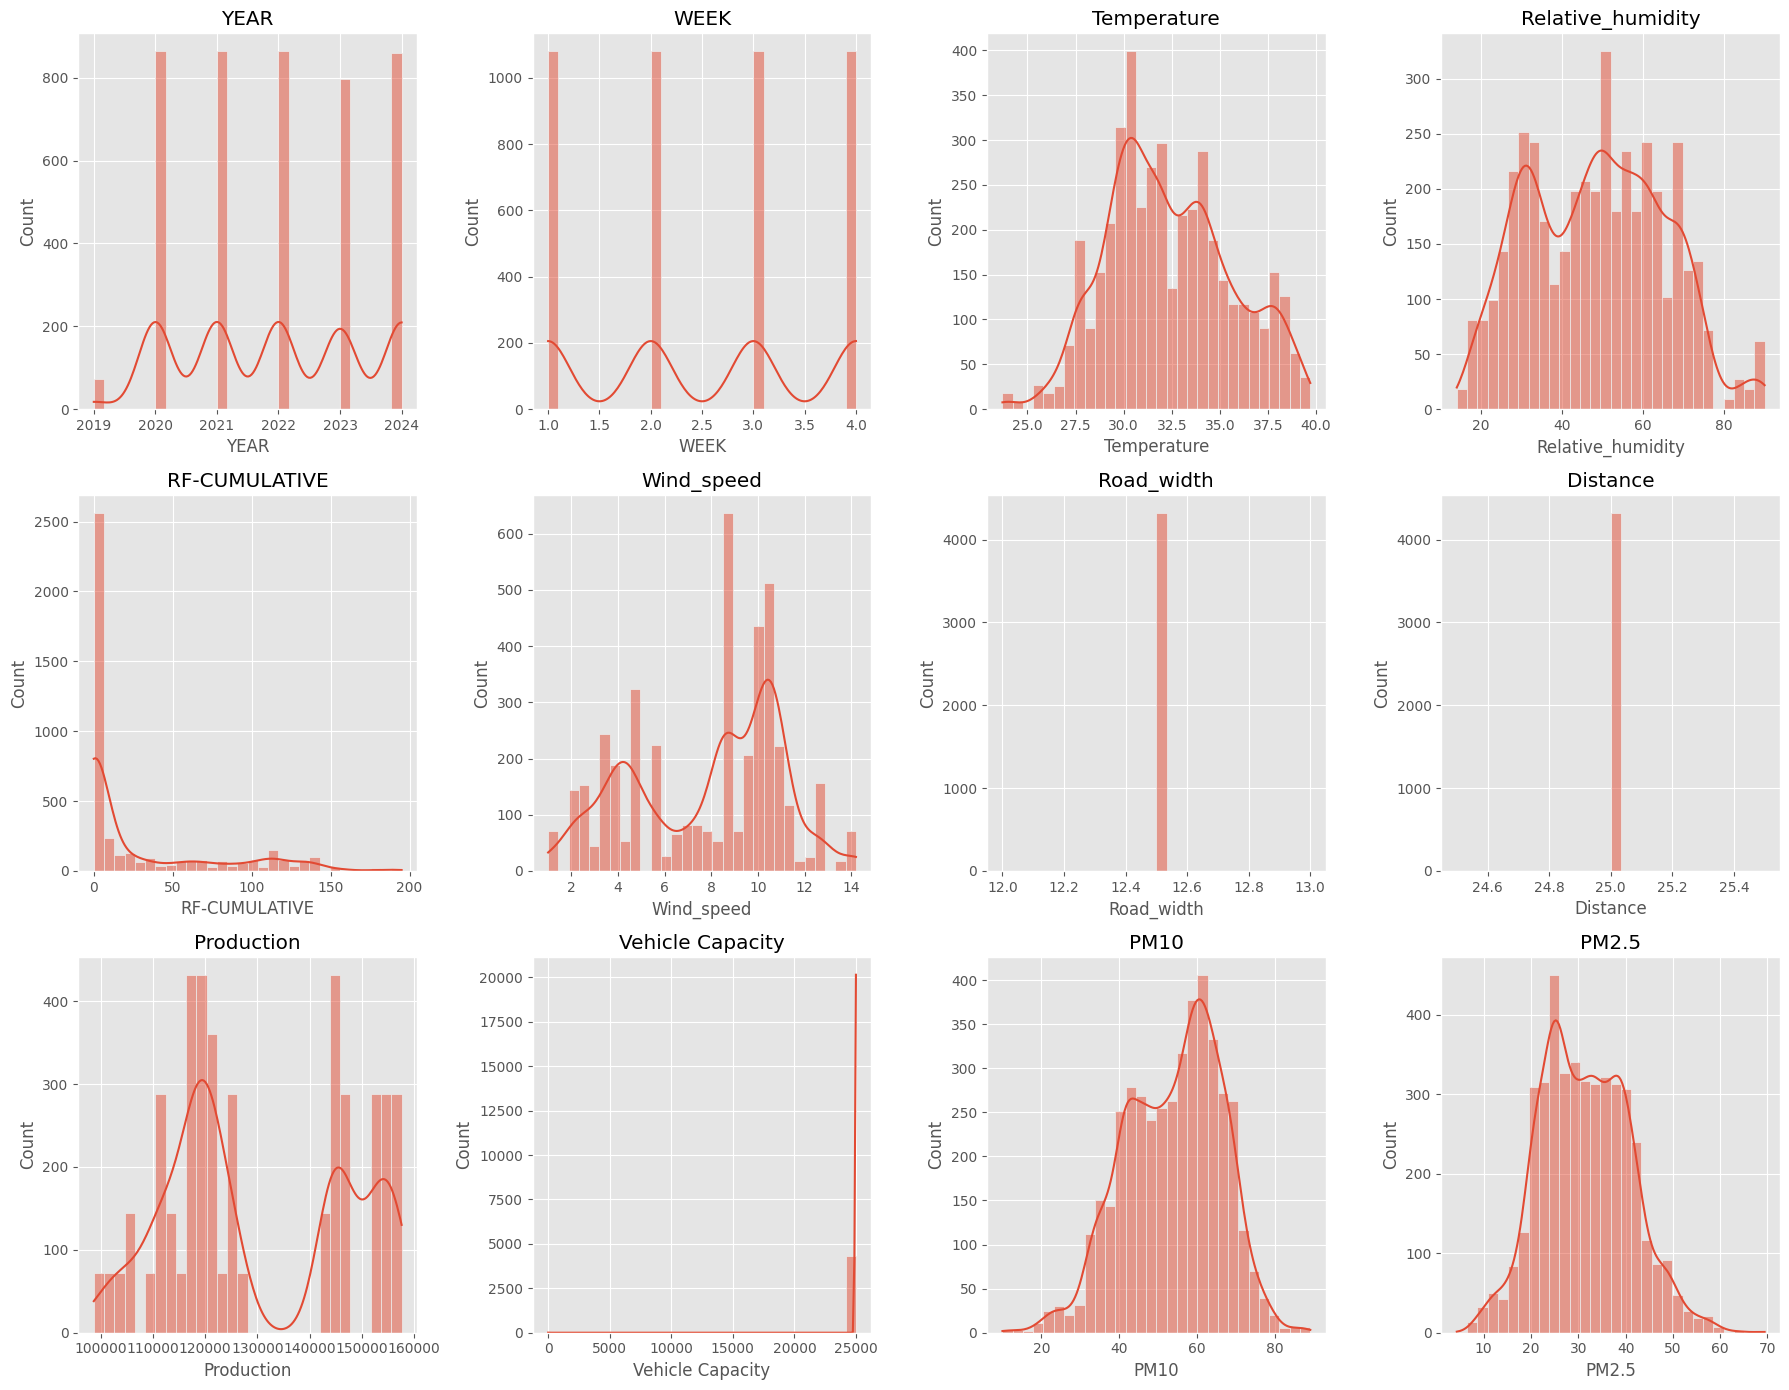

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

fig, axes = plt.subplots(3, 4, figsize=(18, 14))

axes = axes.flatten()

for i, column in enumerate(numerical_features):
    
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=30,
        ax=axes[i]
    )

    axes[i].set_title(column)

plt.tight_layout()

plt.show()

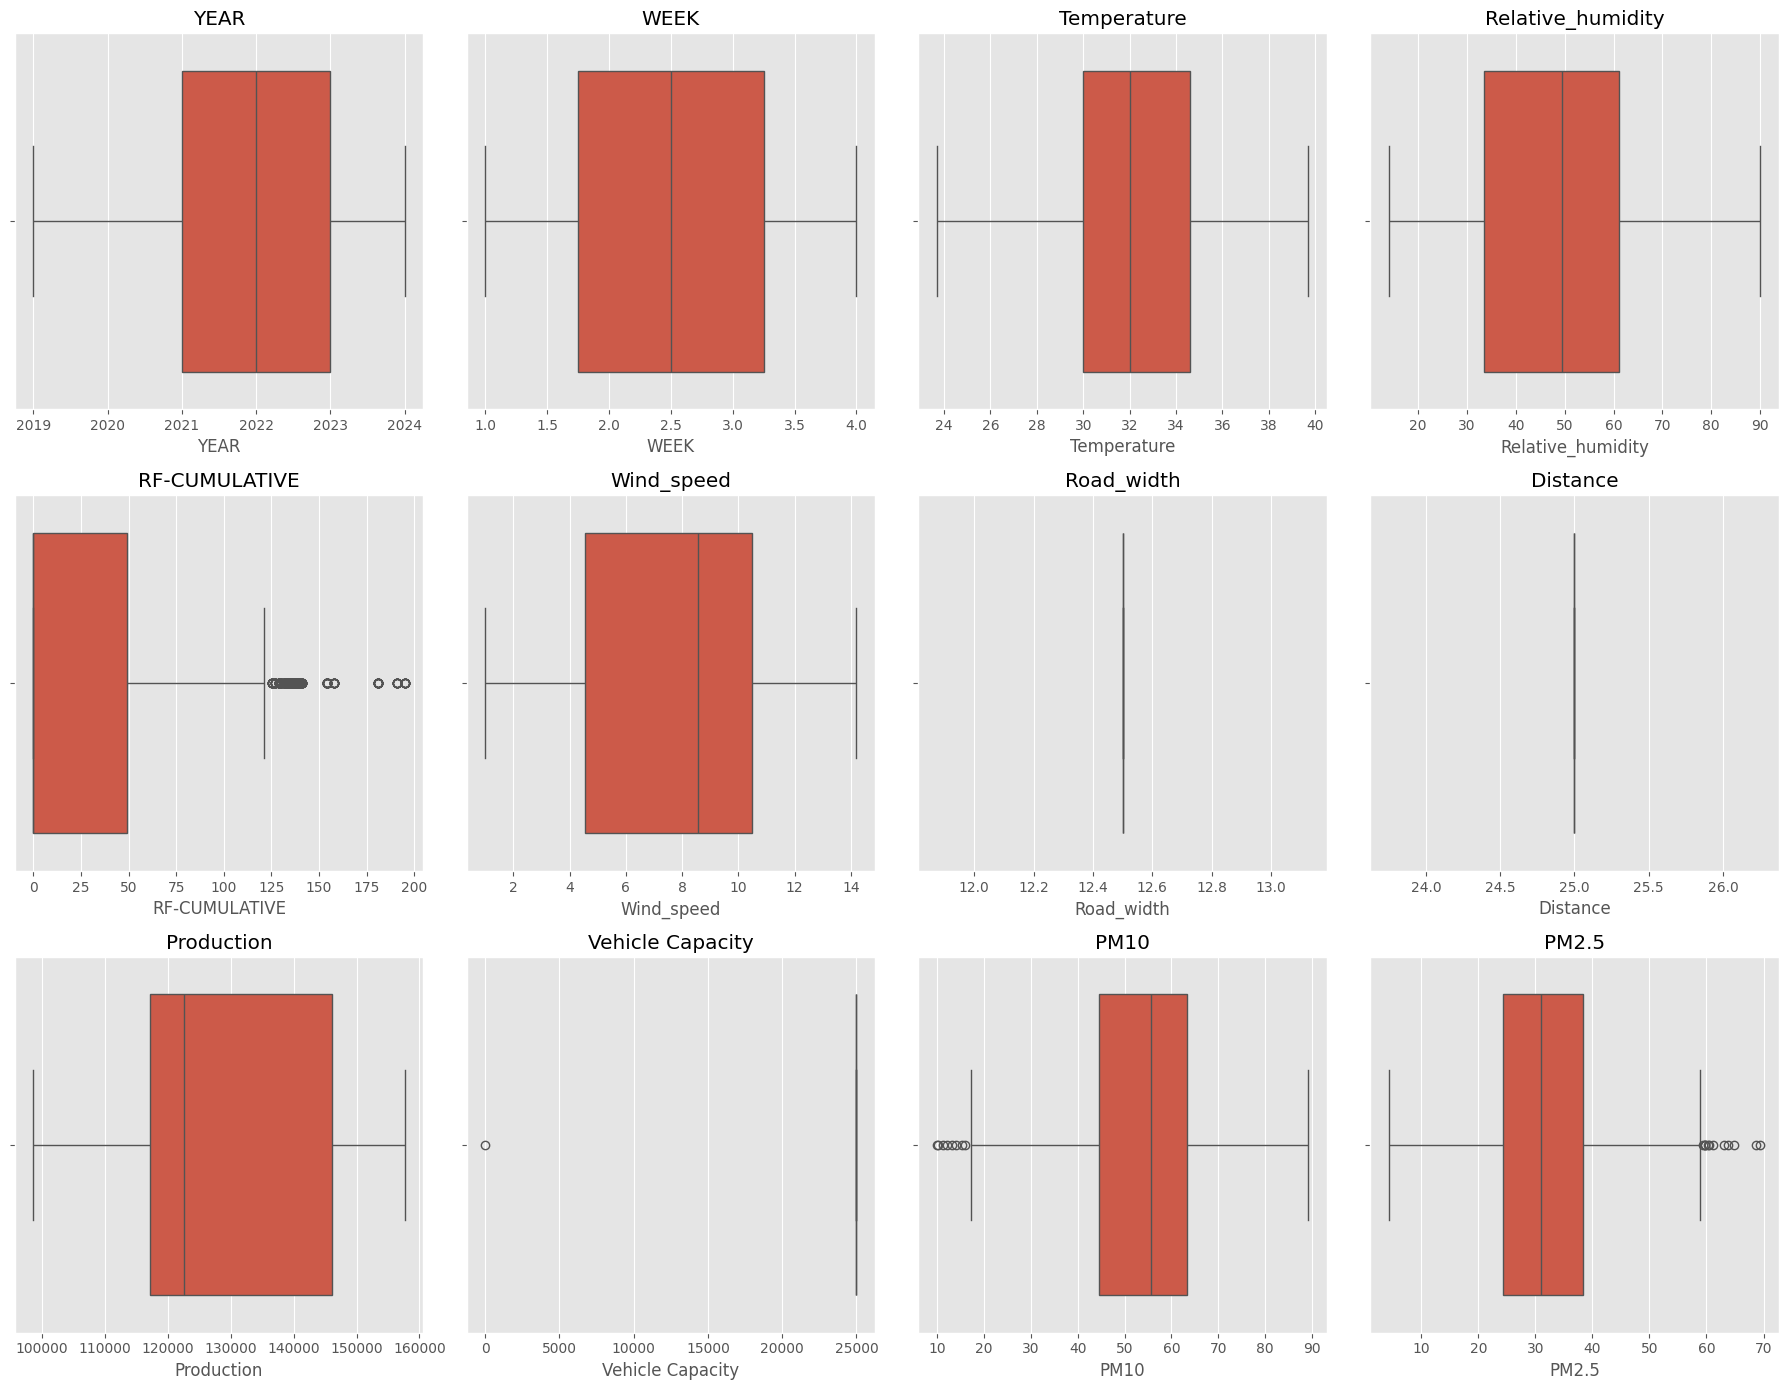

In [9]:
fig, axes = plt.subplots(3, 4, figsize=(18, 14))

axes = axes.flatten()

for i, column in enumerate(numerical_features):

    sns.boxplot(
        x=df[column],
        ax=axes[i]
    )

    axes[i].set_title(column)

plt.tight_layout()

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\1291323037.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


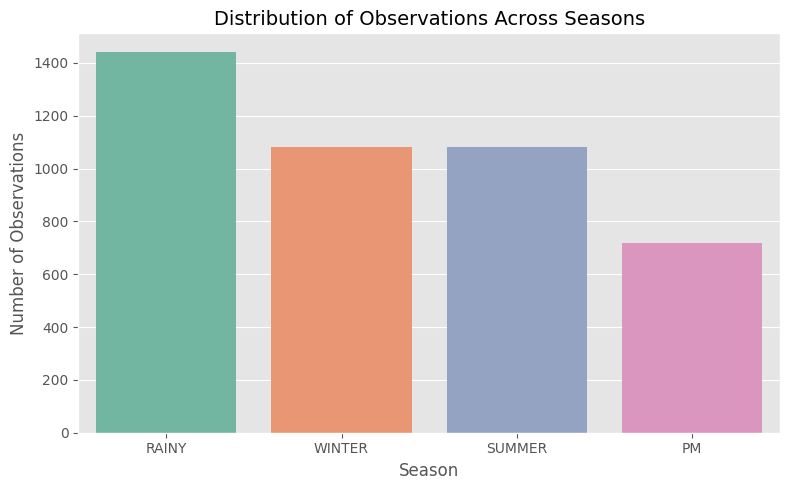

In [10]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='SEASON',
    palette='Set2',
    order=df['SEASON'].value_counts().index
)

plt.title("Distribution of Observations Across Seasons", fontsize=14)
plt.xlabel("Season")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

In [11]:
season_counts = df["SEASON"].value_counts()

display(season_counts)

SEASON
RAINY     1440
WINTER    1080
SUMMER    1080
PM         720
Name: count, dtype: int64

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\2082458742.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


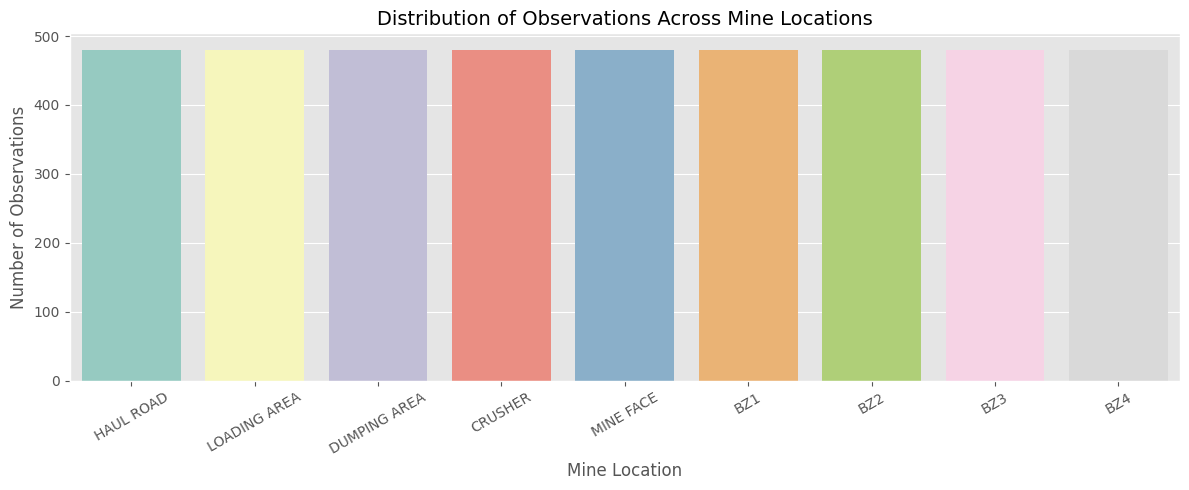

In [12]:
plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x='LOCATION',
    palette='Set3',
    order=df['LOCATION'].value_counts().index
)

plt.title("Distribution of Observations Across Mine Locations", fontsize=14)
plt.xlabel("Mine Location")
plt.ylabel("Number of Observations")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [13]:
location_counts = df["LOCATION"].value_counts()

display(location_counts)

LOCATION
HAUL ROAD       480
LOADING AREA    480
DUMPING AREA    480
CRUSHER         480
MINE FACE       480
BZ1             480
BZ2             480
BZ3             480
BZ4             480
Name: count, dtype: int64

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\3625992529.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


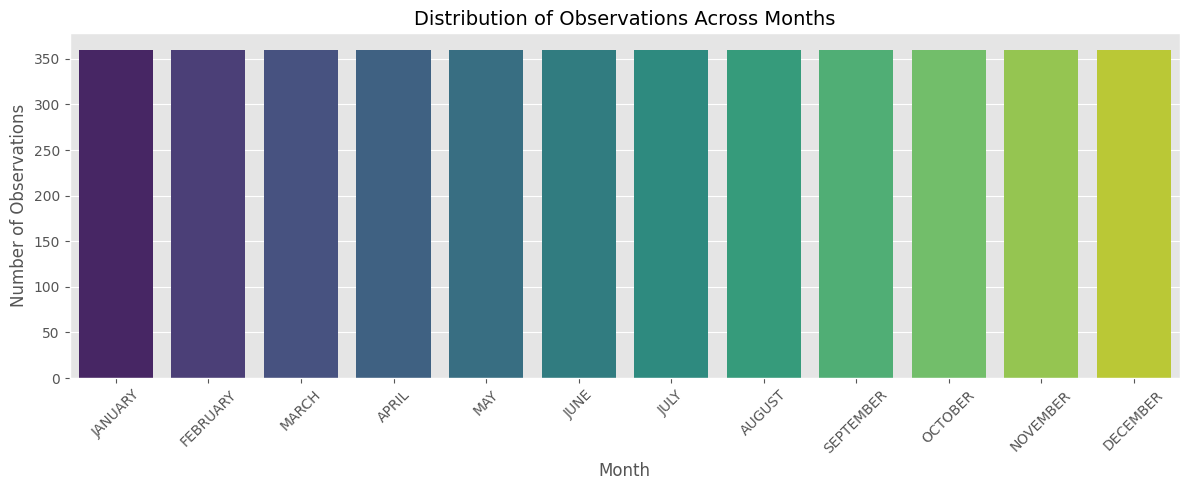

In [14]:
month_order = [
    "JANUARY",
    "FEBRUARY",
    "MARCH",
    "APRIL",
    "MAY",
    "JUNE",
    "JULY",
    "AUGUST",
    "SEPTEMBER",
    "OCTOBER",
    "NOVEMBER",
    "DECEMBER"
]

plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x='MONTH',
    order=month_order,
    palette='viridis'
)

plt.title("Distribution of Observations Across Months", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Number of Observations")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [15]:
month_counts = df["MONTH"].value_counts().reindex(month_order)

display(month_counts)

MONTH
JANUARY      360
FEBRUARY     360
MARCH        360
APRIL        360
MAY          360
JUNE         360
JULY         360
AUGUST       360
SEPTEMBER    360
OCTOBER      360
NOVEMBER     360
DECEMBER     360
Name: count, dtype: int64

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\3750442791.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


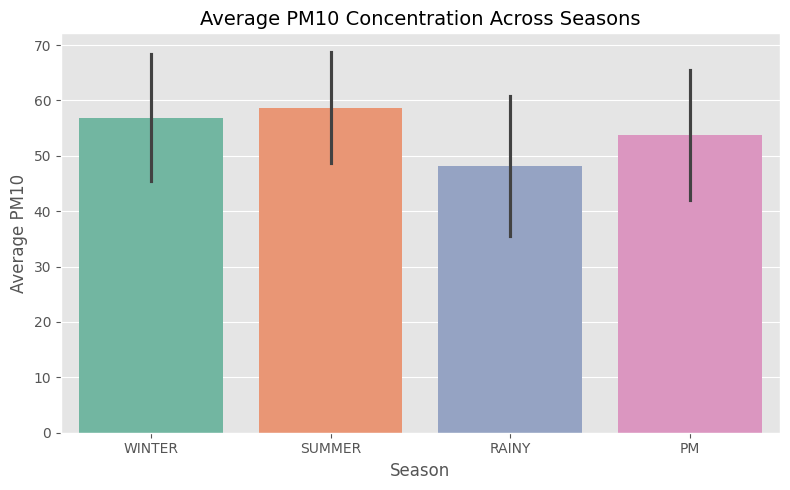

In [16]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="SEASON",
    y="PM10",
    estimator="mean",
    errorbar="sd",
    palette="Set2"
)

plt.title("Average PM10 Concentration Across Seasons", fontsize=14)
plt.xlabel("Season")
plt.ylabel("Average PM10")

plt.tight_layout()
plt.show()

In [17]:
df.iloc[190]

YEAR                   2024.0
SEASON                 WINTER
MONTH                FEBRUARY
LOCATION                  BZ1
WEEK                      3.0
Temperature              35.6
Relative_humidity        19.1
RF-CUMULATIVE             0.0
Wind_speed                1.0
Road_width               12.5
Distance                 25.0
Production           144990.0
Vehicle Capacity        25000
PM10                     65.4
PM2.5                    27.8
Name: 190, dtype: object

In [18]:
invalid = df[pd.to_numeric(df["PM2.5"], errors="coerce").isna()]
display(invalid)

,YEAR,SEASON,MONTH,LOCATION,WEEK,Temperature,Relative_humidity,RF-CUMULATIVE,Wind_speed,Road_width,Distance,Production,Vehicle Capacity,PM10,PM2.5
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,NaN,NaN


In [19]:
df.loc[invalid.index, "PM2.5"]

0   NaN
Name: PM2.5, dtype: float64

In [20]:
df.loc[invalid.index, "PM2.5"] = "38.7"

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\3254062390.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '38.7' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[invalid.index, "PM2.5"] = "38.7"


In [21]:
df["PM2.5"] = pd.to_numeric(df["PM2.5"])

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\2063253829.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


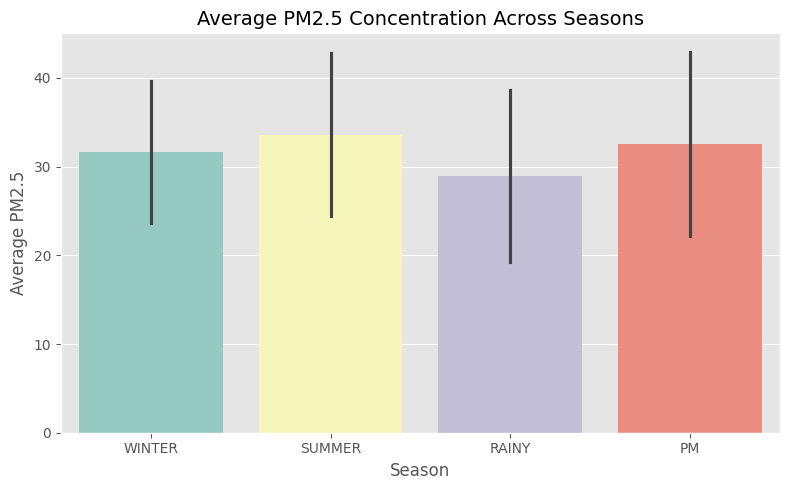

In [22]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="SEASON",
    y="PM2.5",
    estimator="mean",
    errorbar="sd",
    palette="Set3"
)

plt.title("Average PM2.5 Concentration Across Seasons", fontsize=14)
plt.xlabel("Season")
plt.ylabel("Average PM2.5")

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\2641258649.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


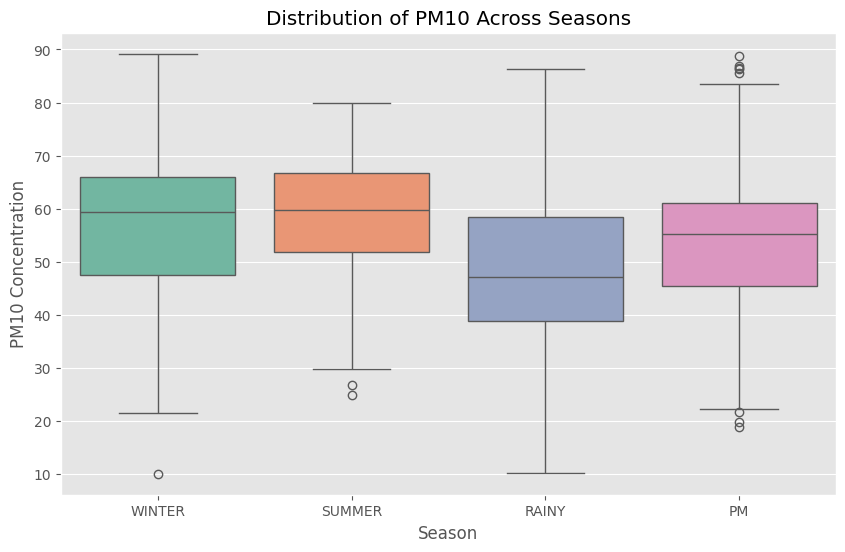

In [23]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="SEASON",
    y="PM10",
    palette="Set2"
)

plt.title("Distribution of PM10 Across Seasons")
plt.xlabel("Season")
plt.ylabel("PM10 Concentration")

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\669106898.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


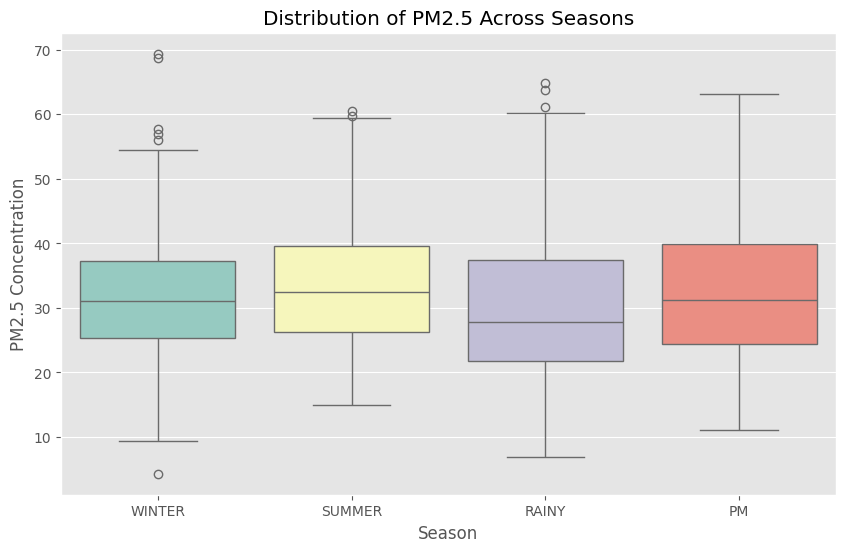

In [24]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="SEASON",
    y="PM2.5",
    palette="Set3"
)

plt.title("Distribution of PM2.5 Across Seasons")
plt.xlabel("Season")
plt.ylabel("PM2.5 Concentration")

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\4277049297.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


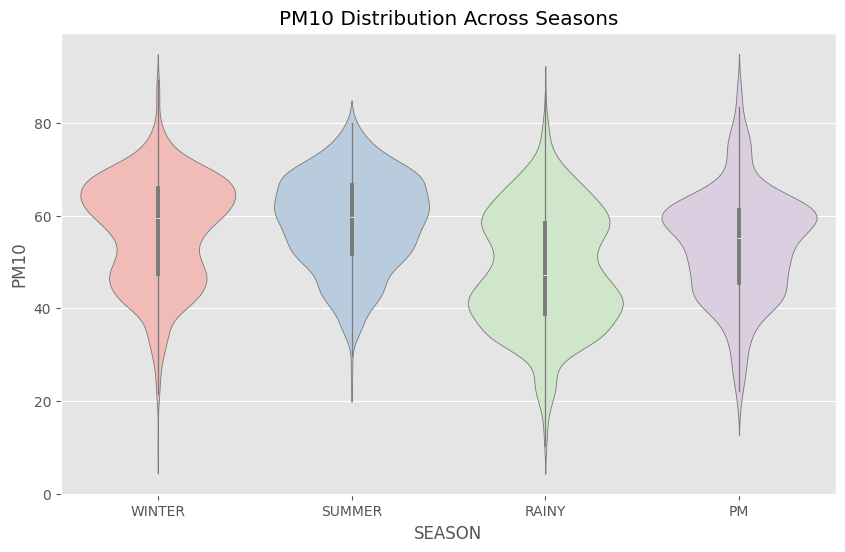

In [25]:
plt.figure(figsize=(10,6))

sns.violinplot(
    data=df,
    x="SEASON",
    y="PM10",
    palette="Pastel1"
)

plt.title("PM10 Distribution Across Seasons")

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\4067323619.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


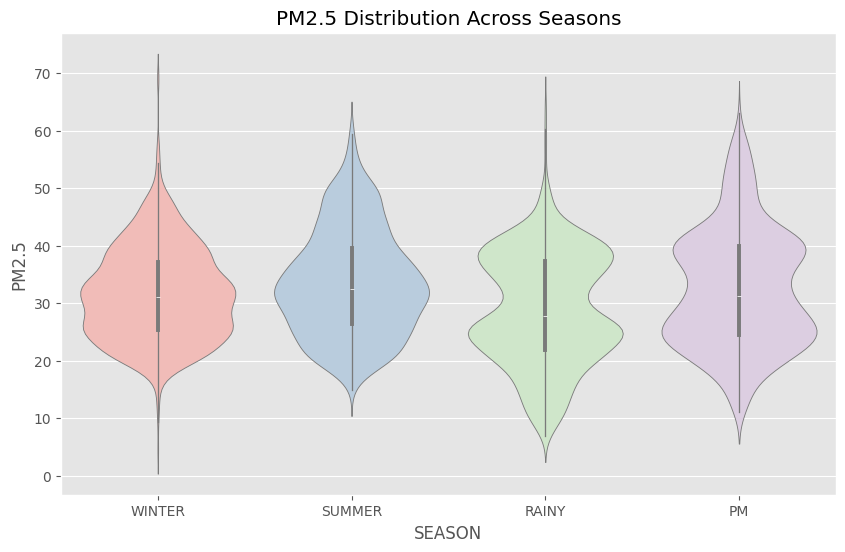

In [26]:
plt.figure(figsize=(10,6))

sns.violinplot(
    data=df,
    x="SEASON",
    y="PM2.5",
    palette="Pastel1"
)

plt.title("PM2.5 Distribution Across Seasons")

plt.show()

In [27]:
season_summary = (
    df.groupby("SEASON")[["PM10", "PM2.5"]]
      .agg(["mean", "median", "std", "min", "max"])
      .round(2)
)

display(season_summary)

PM10                            PM2.5                          
         mean median    std   min   max   mean median    std   min   max
SEASON                                                                  
PM      53.79   55.2  11.67  18.9  88.7  32.56  31.15  10.33  11.1  63.1
RAINY   48.22   47.1  12.65  10.2  86.4  28.94  27.75   9.71   6.9  64.9
SUMMER  58.67   59.7  10.02  24.8  79.9  33.61  32.50   9.18  14.9  60.5
WINTER  56.89   59.4  11.46  10.0  89.2  31.65  31.05   8.03   4.3  69.4

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\3447338795.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


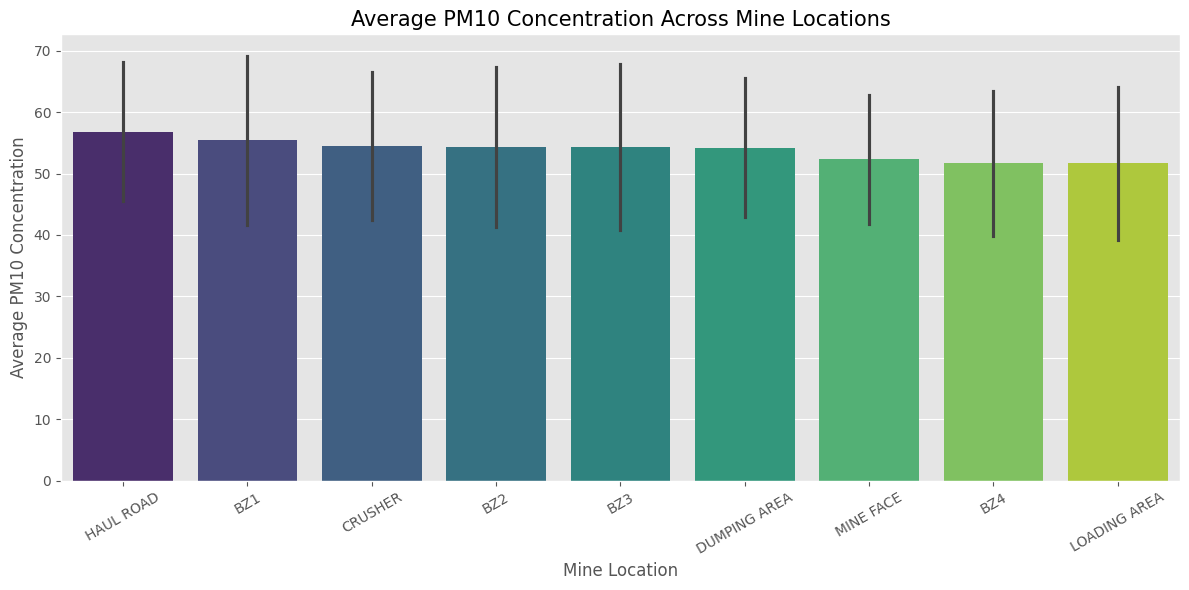

In [28]:
plt.figure(figsize=(12,6))

location_order = (
    df.groupby("LOCATION")["PM10"]
      .mean()
      .sort_values(ascending=False)
      .index
)

sns.barplot(
    data=df,
    x="LOCATION",
    y="PM10",
    order=location_order,
    estimator="mean",
    errorbar="sd",
    palette="viridis"
)

plt.title("Average PM10 Concentration Across Mine Locations", fontsize=15)
plt.xlabel("Mine Location")
plt.ylabel("Average PM10 Concentration")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\3580460547.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


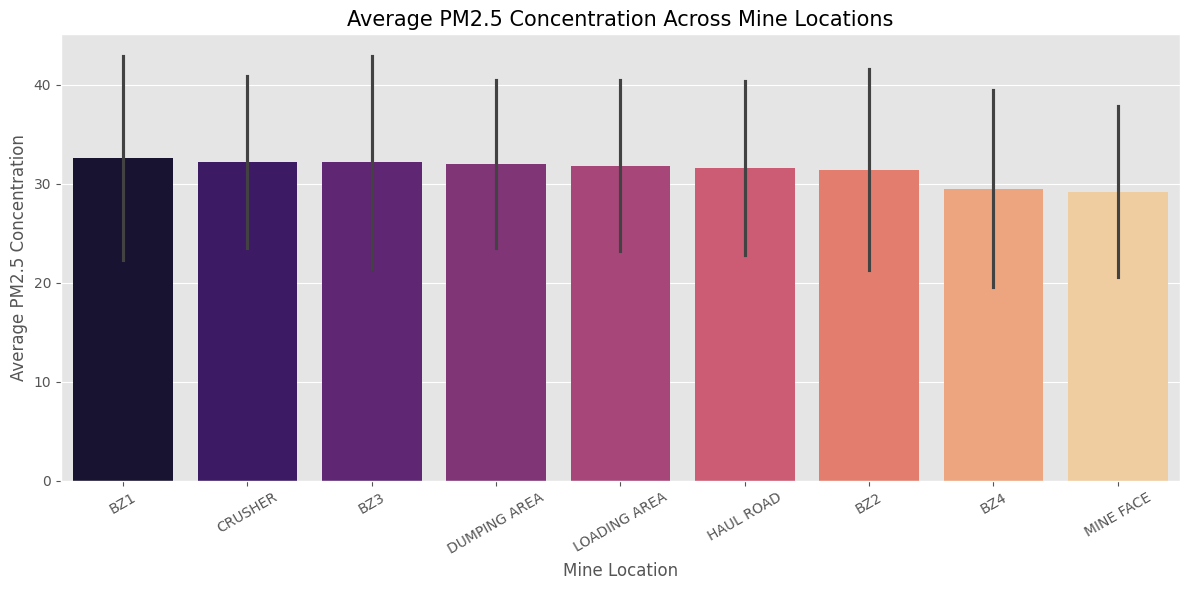

In [29]:
plt.figure(figsize=(12,6))

location_order = (
    df.groupby("LOCATION")["PM2.5"]
      .mean()
      .sort_values(ascending=False)
      .index
)

sns.barplot(
    data=df,
    x="LOCATION",
    y="PM2.5",
    order=location_order,
    estimator="mean",
    errorbar="sd",
    palette="magma"
)

plt.title("Average PM2.5 Concentration Across Mine Locations", fontsize=15)
plt.xlabel("Mine Location")
plt.ylabel("Average PM2.5 Concentration")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\3419003802.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


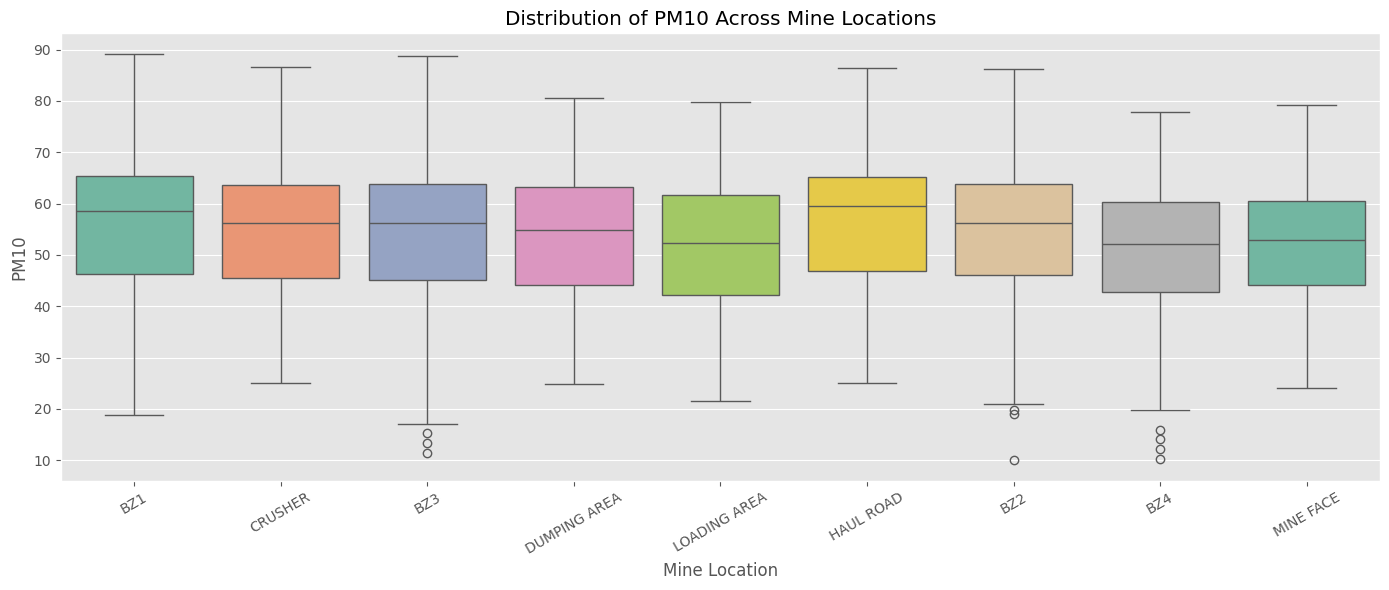

In [30]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df,
    x="LOCATION",
    y="PM10",
    order=location_order,
    palette="Set2"
)

plt.title("Distribution of PM10 Across Mine Locations")
plt.xlabel("Mine Location")
plt.ylabel("PM10")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\78075930.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


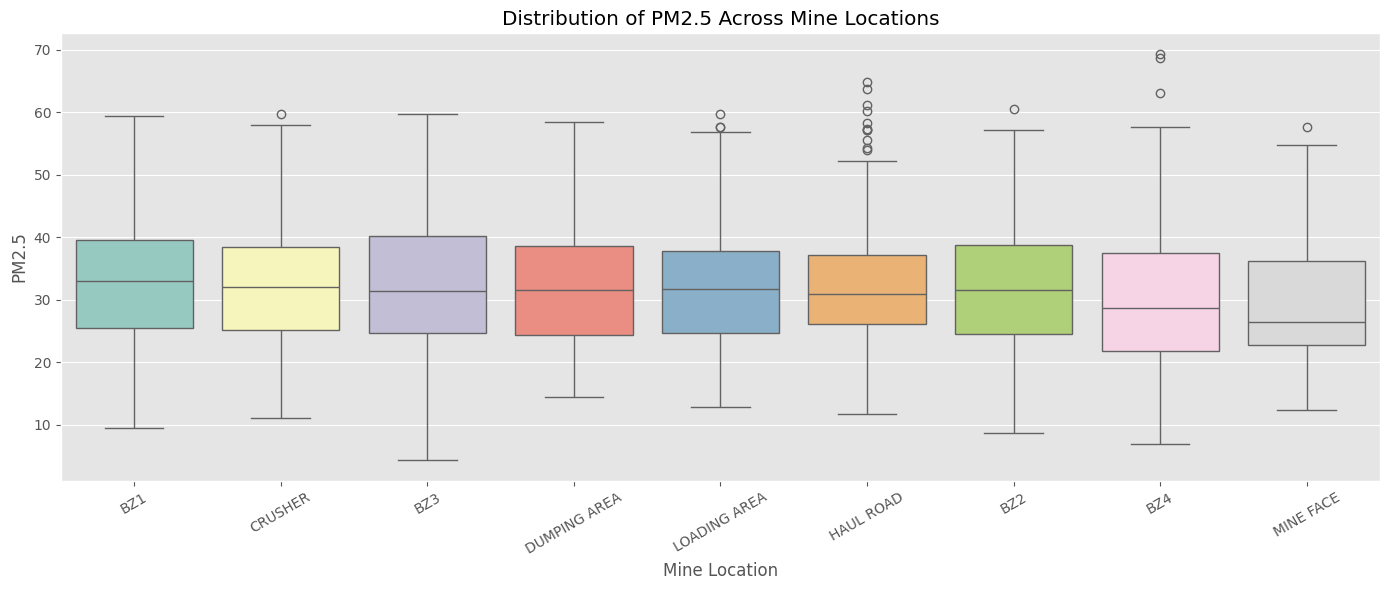

In [31]:
plt.figure(figsize=(14,6))

sns.boxplot(
    data=df,
    x="LOCATION",
    y="PM2.5",
    order=location_order,
    palette="Set3"
)

plt.title("Distribution of PM2.5 Across Mine Locations")
plt.xlabel("Mine Location")
plt.ylabel("PM2.5")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\1974370280.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


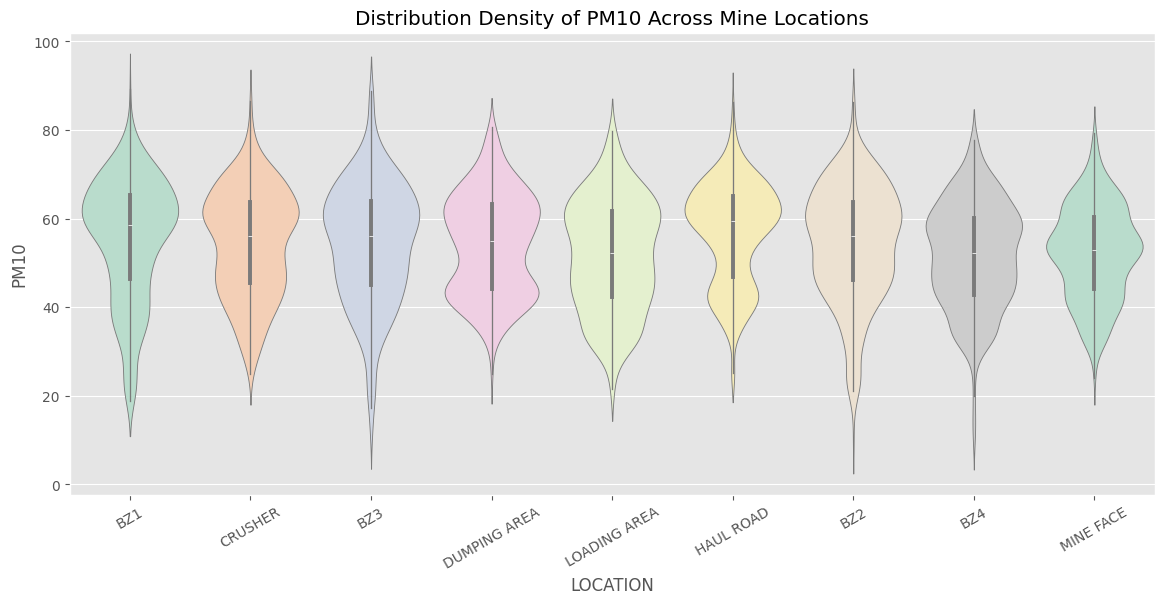

In [32]:
plt.figure(figsize=(14,6))

sns.violinplot(
    data=df,
    x="LOCATION",
    y="PM10",
    order=location_order,
    palette="Pastel2"
)

plt.title("Distribution Density of PM10 Across Mine Locations")

plt.xticks(rotation=30)

plt.show()

C:\Users\DELL\AppData\Local\Temp\ipykernel_14160\3297204571.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


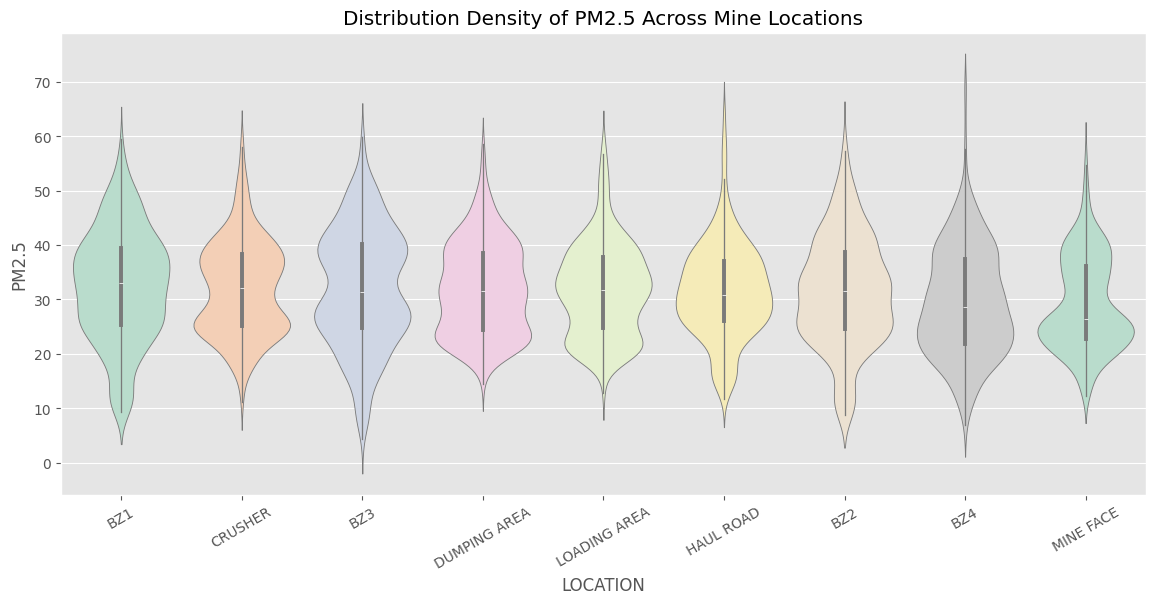

In [33]:
plt.figure(figsize=(14,6))

sns.violinplot(
    data=df,
    x="LOCATION",
    y="PM2.5",
    order=location_order,
    palette="Pastel2"
)

plt.title("Distribution Density of PM2.5 Across Mine Locations")

plt.xticks(rotation=30)

plt.show()

In [34]:
location_summary = (
    df.groupby("LOCATION")[["PM10", "PM2.5"]]
      .agg(["mean", "median", "std", "min", "max"])
      .round(2)
)

display(location_summary)

PM10                             PM2.5                       \
               mean median    std    min   max   mean median    std    min   
LOCATION                                                                     
BZ1           55.41  58.60  13.82  18.90  89.2  32.60  33.00  10.29   9.40   
BZ2           54.36  56.15  13.00  10.00  86.3  31.44  31.60  10.17   8.70   
BZ3           54.34  56.15  13.53  11.38  88.7  32.16  31.35  10.80   4.30   
BZ4           51.70  52.15  11.81  10.20  77.8  29.49  28.65   9.96   6.90   
CRUSHER       54.50  56.12  12.07  25.00  86.6  32.17  32.10   8.71  11.10   
DUMPING AREA  54.23  54.90  11.35  24.80  80.6  32.01  31.55   8.47  14.45   
HAUL ROAD     56.83  59.55  11.29  25.10  86.4  31.60  30.90   8.78  11.64   
LOADING AREA  51.66  52.25  12.51  21.60  79.8  31.82  31.70   8.63  12.90   
MINE FACE     52.31  52.94  10.53  24.10  79.2  29.21  26.40   8.61  12.30   

                     
                max  
LOCATION             
BZ1           59.43  
BZ2           60.50  
BZ3           59.80  
BZ4           69.40  
CRUSHER       59.70  
DUMPING AREA  58.50  
HAUL ROAD     64.90  
LOADING AREA  59.70  
MINE FACE     57.60

In [35]:
location_ranking = (
    df.groupby("LOCATION")[["PM10", "PM2.5"]]
      .mean()
      .sort_values(by="PM10", ascending=False)
      .round(2)
)

display(location_ranking)

,PM10,PM2.5
LOCATION,,
HAUL ROAD,56.83,31.60
BZ1,55.41,32.60
CRUSHER,54.50,32.17
BZ2,54.36,31.44
BZ3,54.34,32.16
DUMPING AREA,54.23,32.01
MINE FACE,52.31,29.21
BZ4,51.70,29.49
LOADING AREA,51.66,31.82


In [36]:
df.columns = df.columns.str.strip()

weather_features = [
    "Temperature",
    "Relative_humidity",
    "RF-CUMULATIVE",
    "Wind_speed"
]

targets = ["PM10", "PM2.5"]

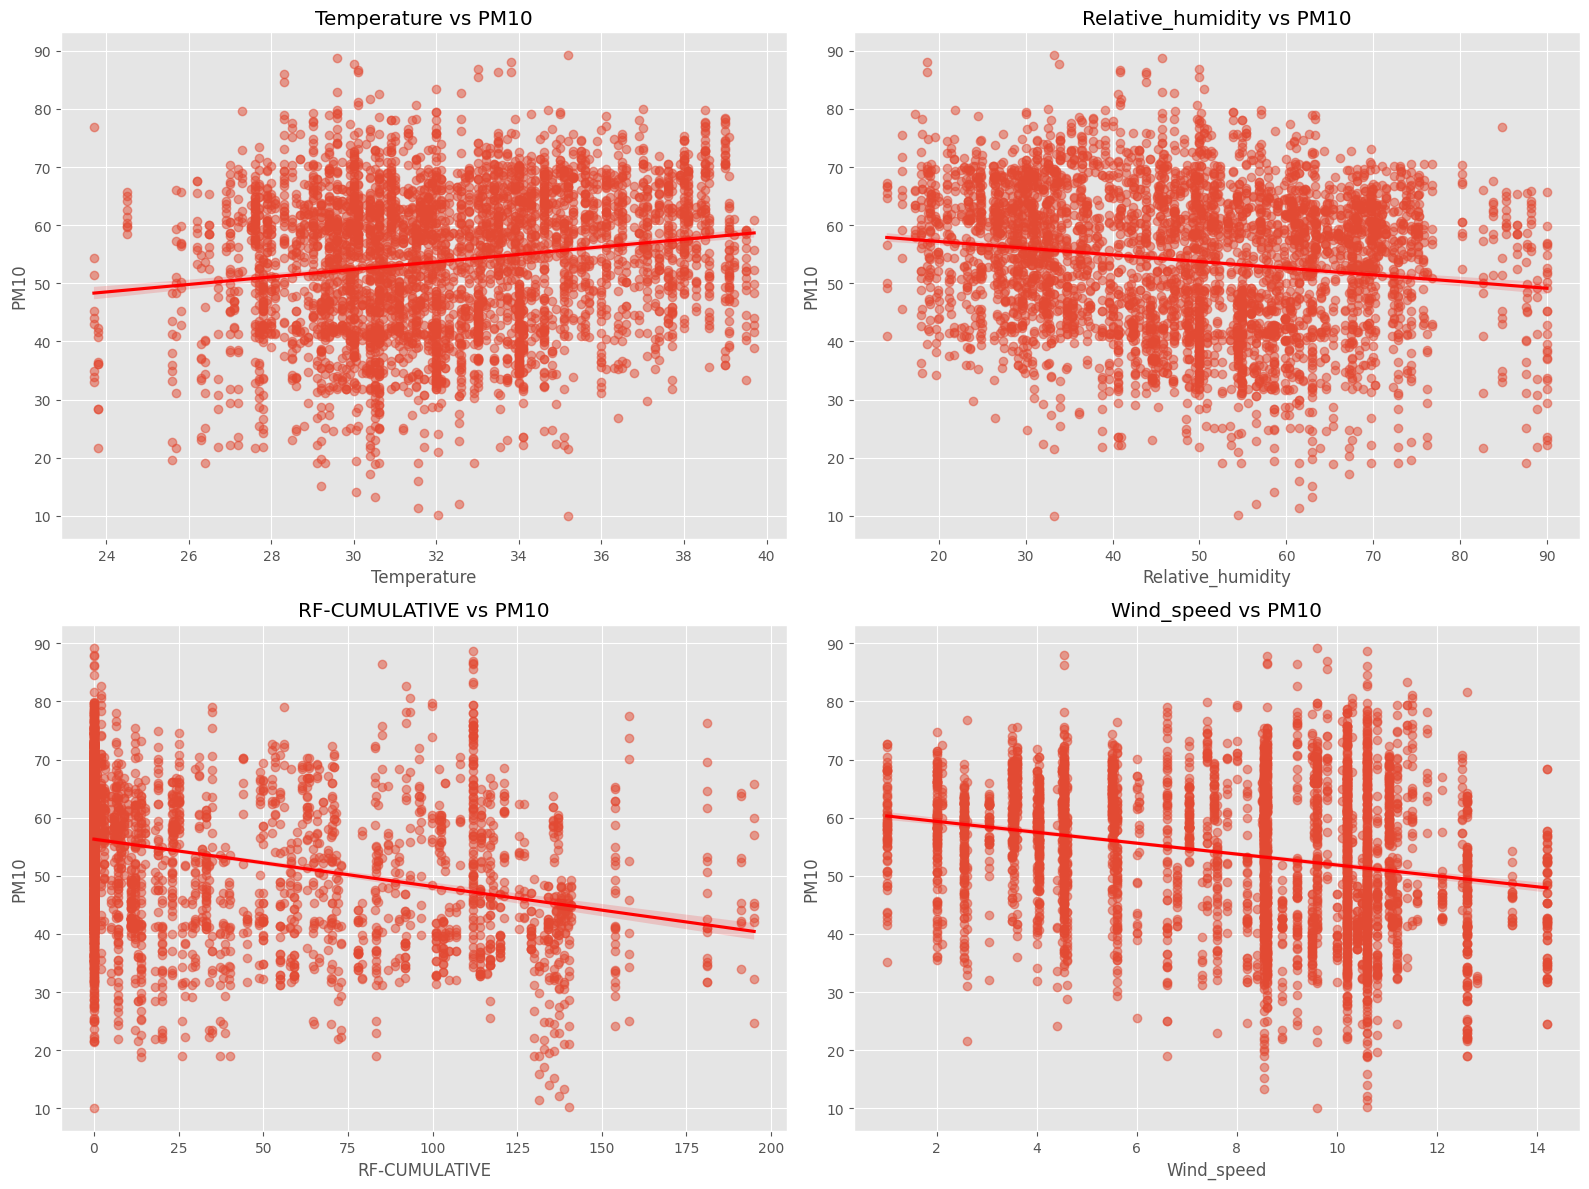

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes = axes.flatten()

for i, feature in enumerate(weather_features):

    sns.regplot(
        data=df,
        x=feature,
        y="PM10",
        scatter_kws={"alpha":0.5},
        line_kws={"color":"red"},
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs PM10")

plt.tight_layout()
plt.show()

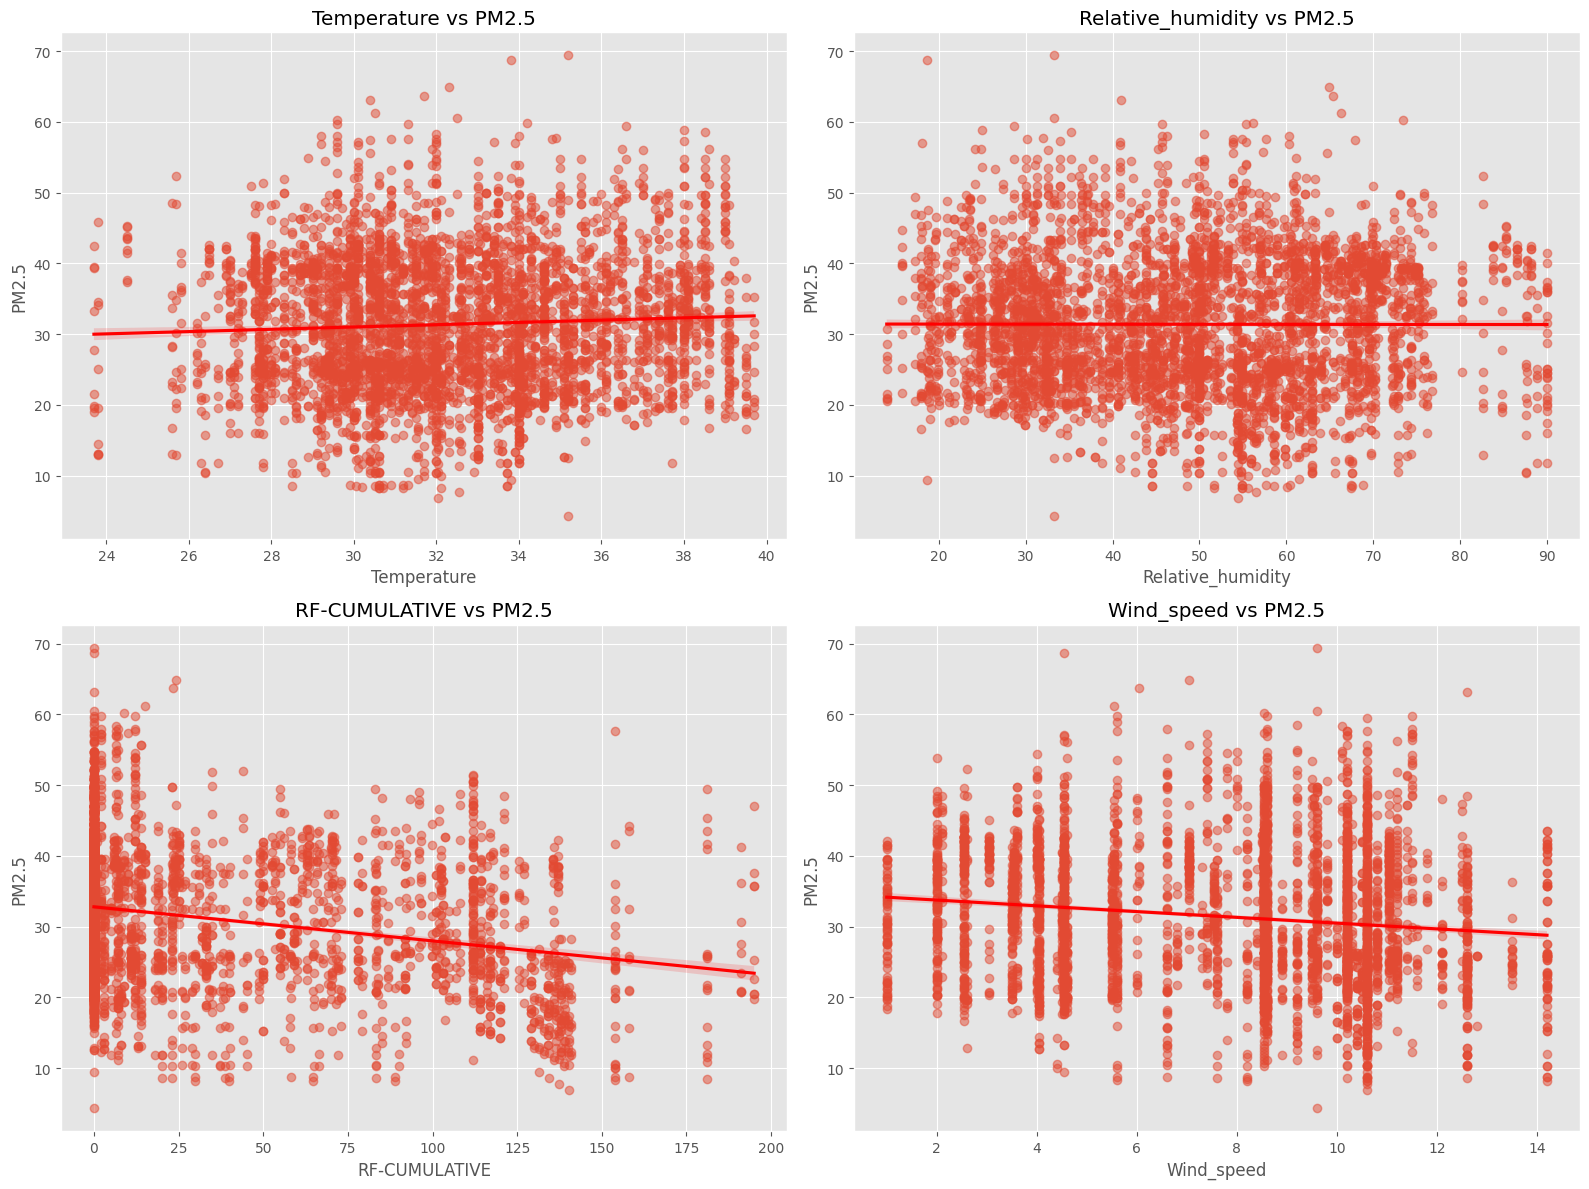

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes = axes.flatten()

for i, feature in enumerate(weather_features):

    sns.regplot(
        data=df,
        x=feature,
        y="PM2.5",
        scatter_kws={"alpha":0.5},
        line_kws={"color":"red"},
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs PM2.5")

plt.tight_layout()
plt.show()

In [41]:
df.columns = df.columns.str.strip()

mine_features = [
    "Road_width",
    "Distance",
    "Production",
    "Vehicle Capacity"
]

targets = ["PM10", "PM2.5"]

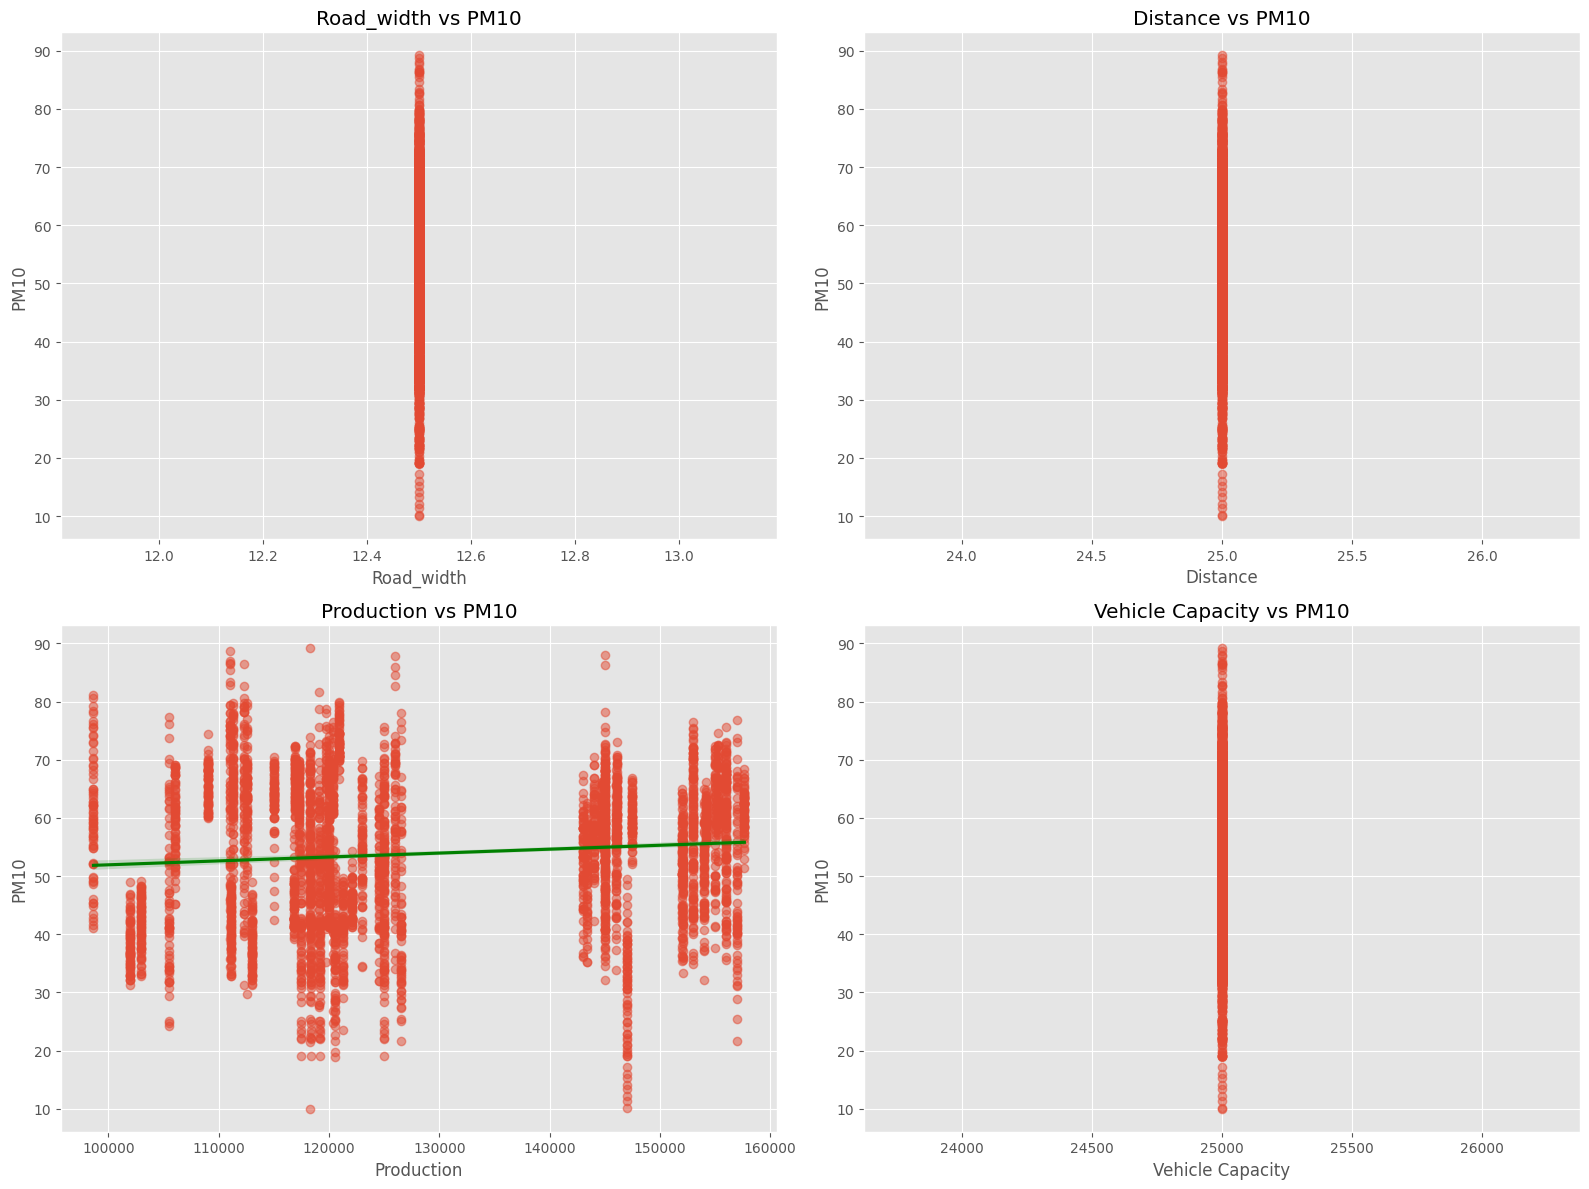

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes = axes.flatten()

for i, feature in enumerate(mine_features):

    sns.regplot(
        data=df,
        x=feature,
        y="PM10",
        scatter_kws={"alpha":0.5},
        line_kws={"color":"green"},
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs PM10")

plt.tight_layout()
plt.show()

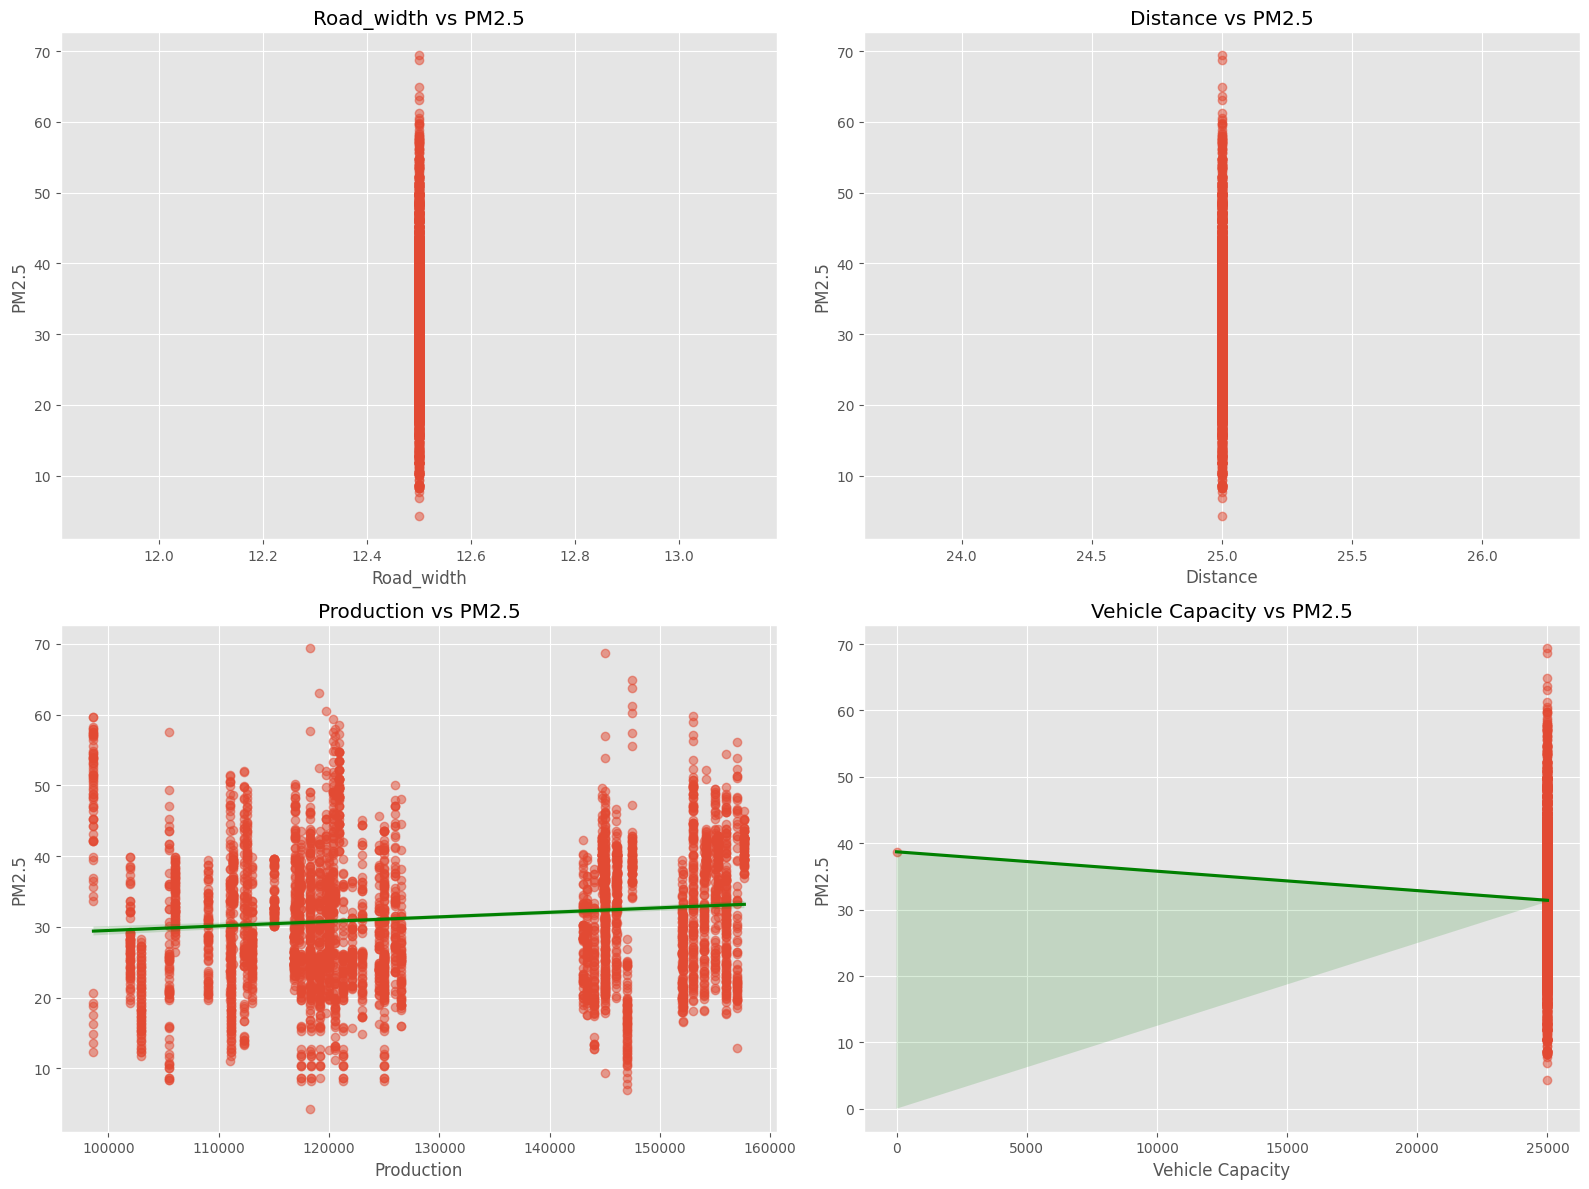

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

axes = axes.flatten()

for i, feature in enumerate(mine_features):

    sns.regplot(
        data=df,
        x=feature,
        y="PM2.5",
        scatter_kws={"alpha":0.5},
        line_kws={"color":"green"},
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs PM2.5")

plt.tight_layout()
plt.show()

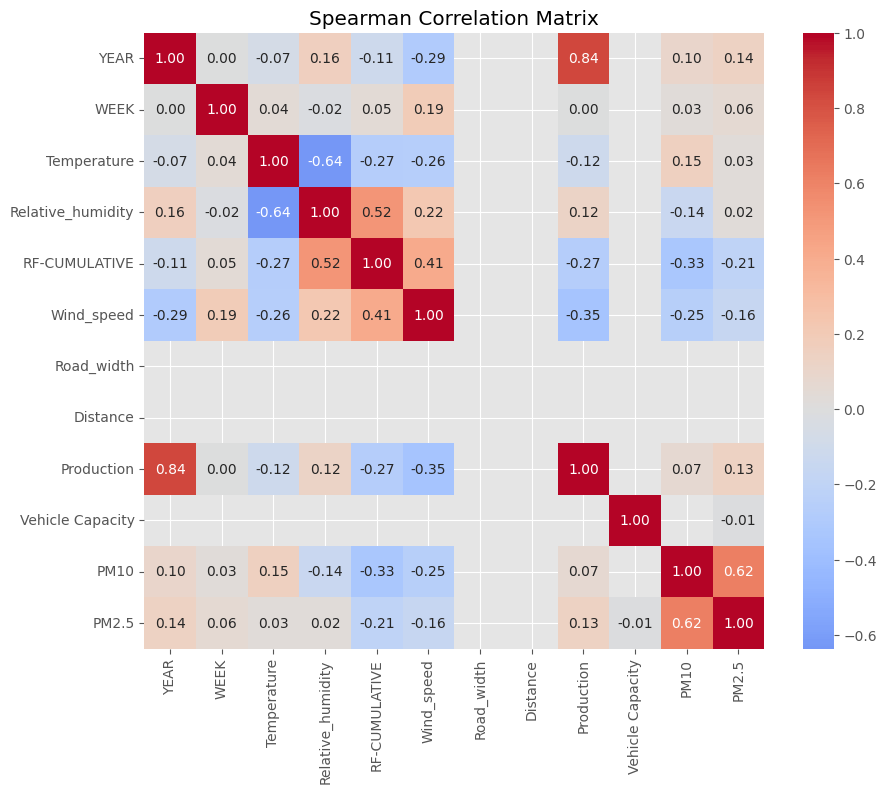

In [45]:
plt.figure(figsize=(10,8))

corr = df.corr(method="spearman", numeric_only=True)

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Spearman Correlation Matrix")

plt.show()

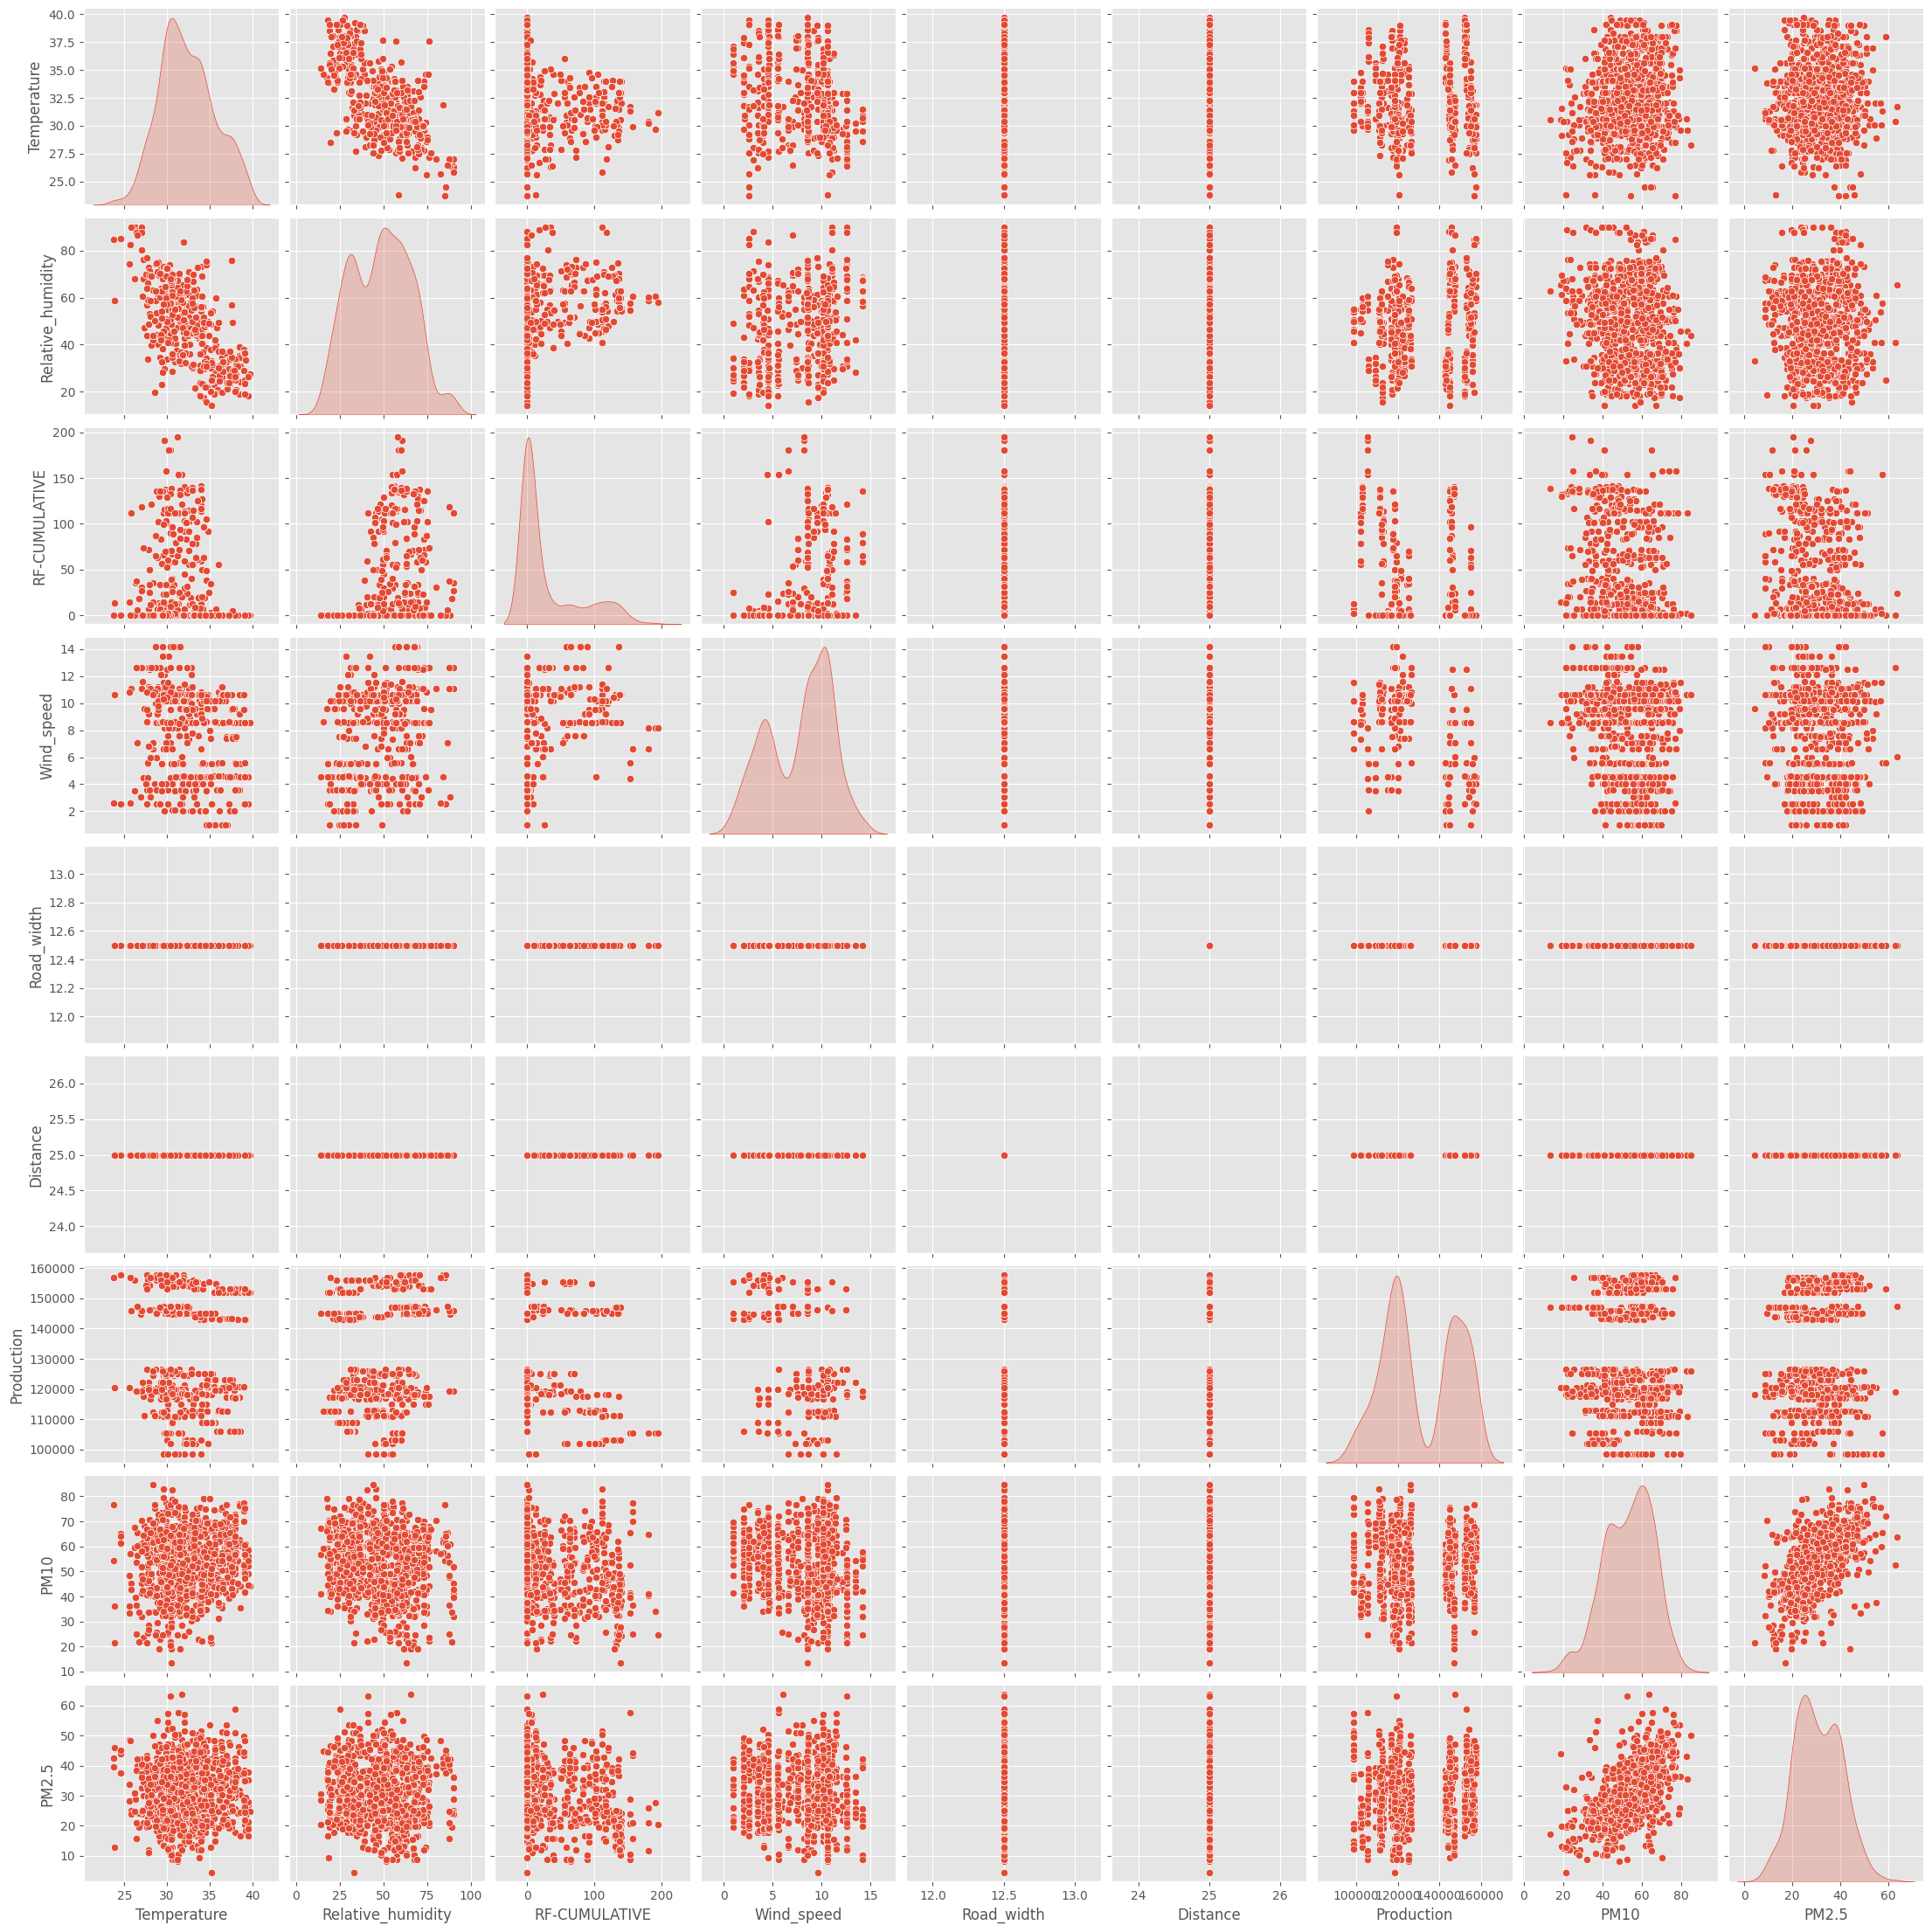

In [47]:
selected_columns = [
    "Temperature",
    "Relative_humidity",
    "RF-CUMULATIVE",
    "Wind_speed",
    "Road_width",
    "Distance",
    "Production",
    "PM10",
    "PM2.5",
]

sns.pairplot(
    df[selected_columns].sample(1000, random_state=42),
    diag_kind="kde"
)

plt.show()

In [48]:
corr_pm10 = df[weather_features + ["PM10"]].corr()["PM10"][:-1]

corr_pm25 = df[weather_features + ["PM2.5"]].corr()["PM2.5"][:-1]

display(corr_pm10.sort_values(key=abs, ascending=False))

display(corr_pm25.sort_values(key=abs, ascending=False))

Production          0.095677
Road_width               NaN
Distance                 NaN
Vehicle Capacity         NaN
Name: PM10, dtype: float64

Production          0.118923
Vehicle Capacity   -0.011736
Road_width               NaN
Distance                 NaN
Name: PM2.5, dtype: float64